In [10]:
import pandas as pd
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

In [11]:
df = pd.read_csv("/content/IMDB Dataset.csv")

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [12]:
print(df.shape)

(50000, 2)


In [13]:
print(df.isnull().sum())

review       0
sentiment    0
dtype: int64


In [14]:
print(df.duplicated().sum())

418


In [15]:
print(df["sentiment"].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [16]:
print(df["review"].str.len().describe())

count    50000.000000
mean      1308.114440
std        989.661099
min         32.000000
25%        698.000000
50%        969.500000
75%       1588.000000
max      13704.000000
Name: review, dtype: float64


In [17]:
#cleaning the data

In [18]:
df = df.drop_duplicates().reset_index(drop=True)

print(df.shape)

(49582, 2)


In [19]:
def remove_html(text):
    return re.sub(r"<.*?>", "", text)

df["review"] = df["review"].apply(remove_html)

In [20]:
df["review"] = df["review"].str.lower()

In [21]:
df.head()

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


In [22]:
df[df["review"].str.contains("<br>", regex=False)].head()

,review,sentiment


In [23]:
df["sentiment"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

In [24]:
df.head()

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production. the filming tec...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically there's a family where a little boy ...,0
4,"petter mattei's ""love in the time of money"" is...",1


In [25]:
X = df["review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [26]:
vectorizer = CountVectorizer(stop_words="english")
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

In [27]:
from sklearn.svm import LinearSVC

In [30]:
model = LinearSVC()

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
model.fit(X_train_vectorized, y_train)

LinearSVC()

In [38]:
y_pred = model.predict(X_test_vectorized)

In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [40]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [42]:
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

Accuracy: 0.86
Precision: 0.86
Recall: 0.87
F1 Score: 0.86


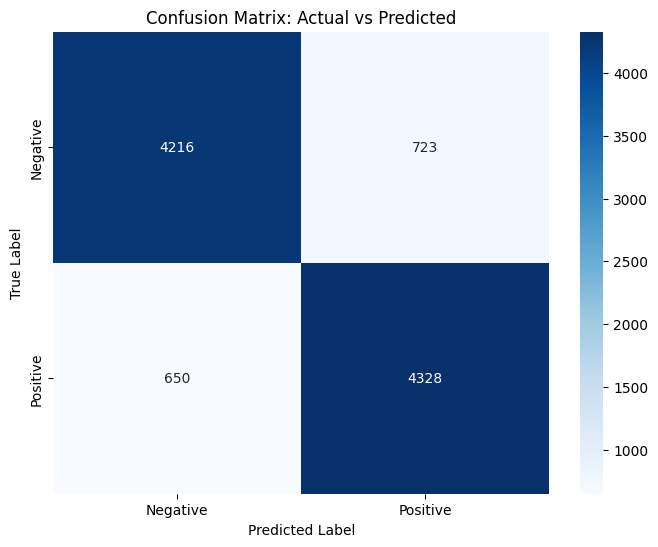

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

confusion_mat = confusion_matrix(y_test, y_pred)

class_names = ['Negative', 'Positive'] # Assuming 0 is Negative and 1 is Positive

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix: Actual vs Predicted')
plt.show()

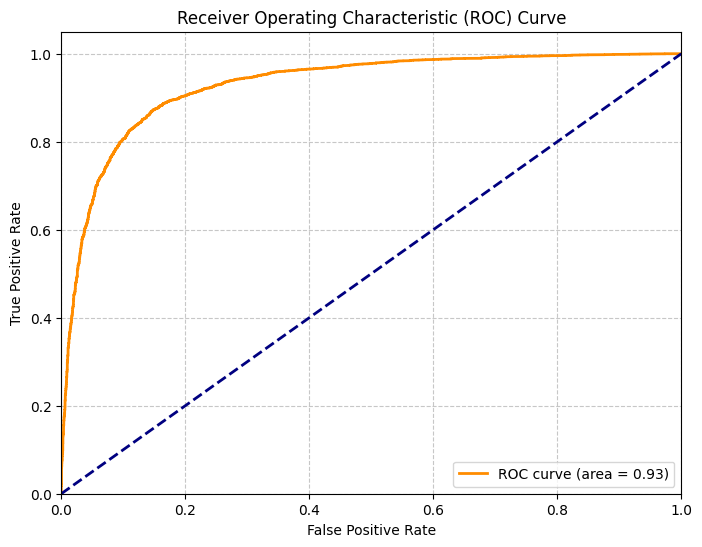

In [48]:
from sklearn.metrics import roc_curve, auc

# Get decision function scores for the positive class
y_score = model.decision_function(X_test_vectorized)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [44]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4939
           1       0.86      0.87      0.86      4978

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917

